#**Нейронные сети в квантовой теории**

# **A**I **M**eets **K**nowledge

Физически-информированные нейронные сети (PINNs) — это методы машинного обучения, которые объединяют возможности нейронных сетей с законами физики для решения дифференциальных уравнений. В отличие от традиционных Data-Driven подходов, которые полагаются только на данные, PINNs включают физическую информацию в процесс обучения. Это позволяет использовать остаточную невязку уравнений, начальные и граничные условия в качестве регуляризаторов и ограничений при оптимизации параметров сети. Благодаря этому гибридному Physics-Driven подходу, PINNs могут решать как прямые, так и обратные задачи, работать с неполными и зашумленными данными, а также восстанавливать неизвестные параметры моделей.

# **PINN (физически-информированные нейросети)**

# Исторический контекст

Концепция применения нейронных сетей для решения дифференциальных уравнений зародилась задолго до всплеска популярности глубокого обучения. Важный вклад в развитие этой идеи внесла статья Лагариса и его коллег (I. E. Lagaris, A. Likas, D. I. Fotiadis), опубликованная в 1998 году. Авторы предложили формировать пробное решение дифференциального уравнения как сумму двух частей: первая часть строго удовлетворяет начальным и граничным условиям без использования настраиваемых параметров, тогда как вторая реализуется с помощью многослойного перцептрона, чьи веса подлежат оптимизации. Таким образом, граничные условия выполнялись автоматически, а нейронная сеть обучалась минимизировать невязку дифференциального уравнения. Лагарис показал, что нейросетевые аппроксимации могут быть эффективно применены для решения краевых задач в сложных геометрических областях. Однако прогресс в этой области был замедлен из-за отсутствия эффективных алгоритмов автоматического дифференцирования и вычислительных ресурсов, необходимых для обучения глубоких моделей.


Настоящий прогресс наступил почти два десятилетия спустя, в 2019 году, когда Мазьяр Райсси, Парис Пердикарис и Джордж Карниадакис опубликовали фундаментальную работу, предложившую современный унифицированный подход к созданию физически-информированных нейронных сетей. В этой работе была разработана общая структура функции потерь, включающая невязку дифференциальных уравнений в частных производных, начальные и граничные условия, а также данные наблюдений. Авторы продемонстрировали, как обратное распространение ошибки и автоматическое дифференцирование позволяют одновременно обучать нейросеть и оценивать неизвестные параметры модели. Именно эта статья стала отправной точкой для бурного развития научного машинного обучения, стимулировав появление множества модификаций и расширений данного метода. Ключевыми факторами успеха PINNs на сегодняшний день стали широкое распространение библиотек автоматического дифференцирования (например, TensorFlow, PyTorch, JAX) и доступность высокопроизводительных графических процессоров.

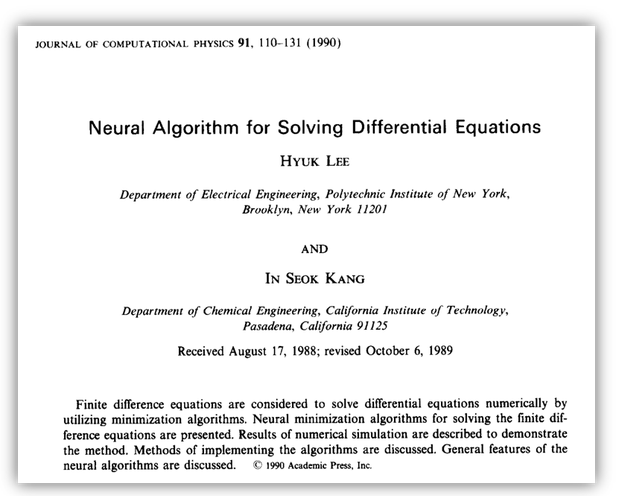

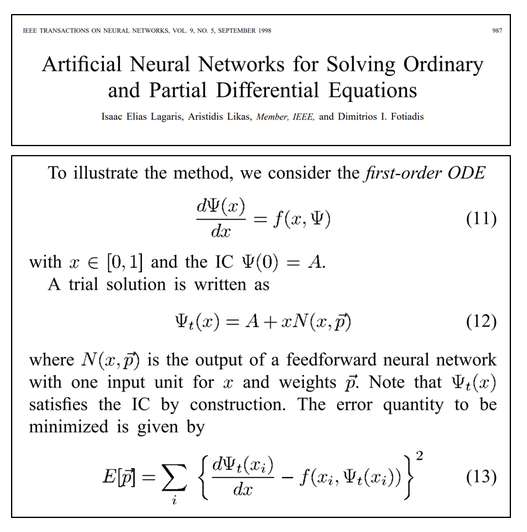

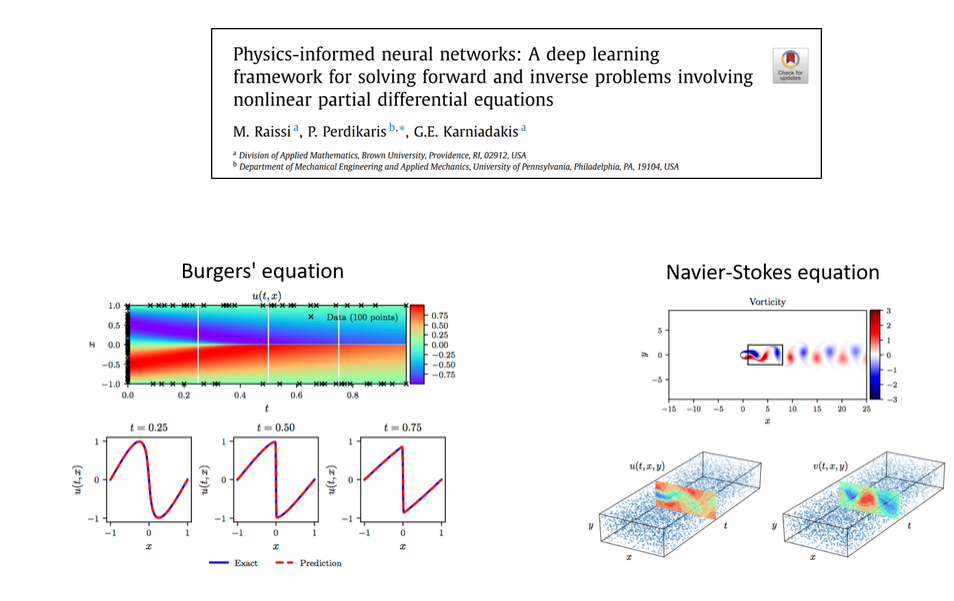

Можно вставить и корреляции

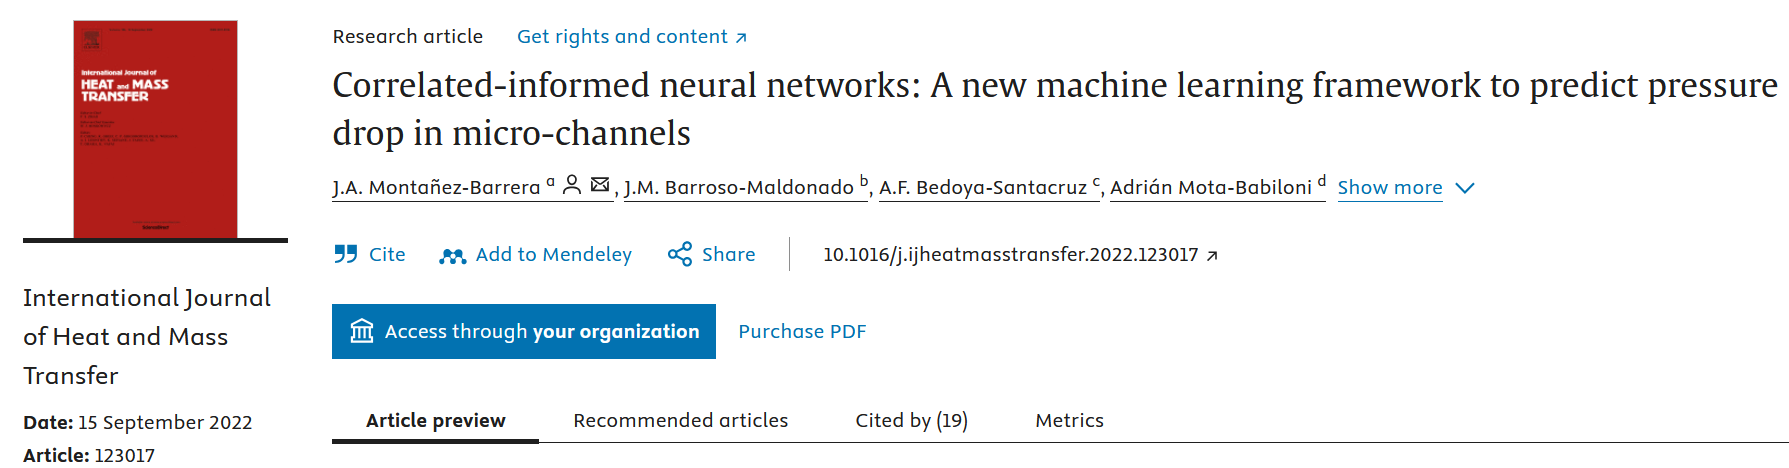

# 2. Архитектура нейросетей, основанных на физических принципах (Physics-informed Neural Networks, PINN)


- Нейронная сеть как универсальный аппроксиматор функций

- Дано
    - Некоторые измеренные данные из начальных и граничных условий
    - ОДУ или УЧП

<br>

$$\frac{\partial u}{\partial t} - \lambda \frac{\partial^2 u}{\partial x^2} = 0$$

<br>

- Добавление ограничений для регуляризации
    - Регуляризовано с учетом физических законов, но согласовано с разреженными данными

<br>

$$
\begin{align*}
\mathcal{L} &= \alpha_{\text{data}}  \mathcal{L}_{\text{data}} + \alpha_{\text{PDE}} \mathcal{L}_{\text{PDE}}\\\\\\
\mathcal{L}_{\text{data}} &= \frac{1}{N_{\text{data}}} \sum \left(u(x,t) - u \right)^2 \\
\mathcal{L}_{\text{PDE}} &= \frac{1}{N_{\text{PDE}}} \sum \left(\frac{\partial u}{\partial t} - \lambda \frac{\partial^2 u}{\partial x^2} \right)^2
\end{align*}
$$


<br><br>
<center>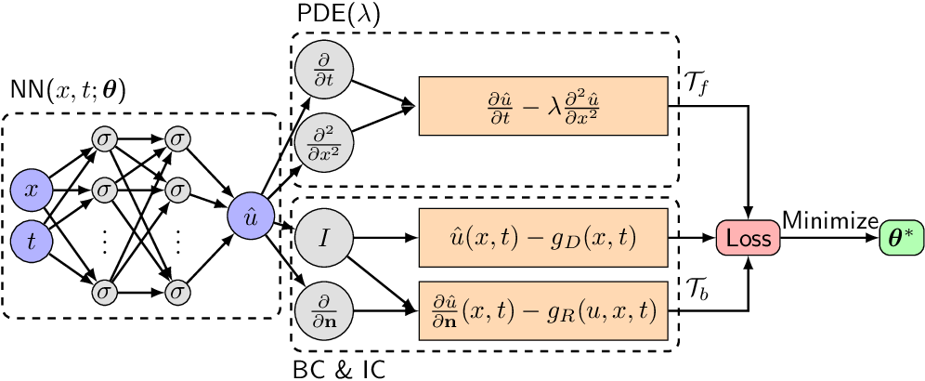</center>
<br>

# 3. Метод решения обыкновенных дифференциальных уравнений с помощью нейронных сетей

## 3.1. Предпосылки

[Этот метод был впервые предложен Лагарисом и др. в 1998 году.](https://arxiv.org/pdf/physics/9705023.pdf) Идея состоит в том, чтобы решать дифференциальные уравнения с помощью нейронных сетей, представляя решение в виде нейронной сети и обучая её таким образом, чтобы она удовлетворяла условиям, необходимым для решения дифференциального уравнения.

Рассмотрим систему обыкновенных дифференциальных уравнений

$$
{u^\prime} = f(u,t)
$$

при $t \in [0, 1]$ и известном начальном условии $u(0) = u_0$.

Чтобы решить эту задачу, мы аппроксимируем решение с помощью нейронной сети:

$$
{\text{NN}(t)} \approx {u(t)}
$$

<br>

Если бы $\text{NN}(t)$ было истинным решением, то выполнялось бы условие $\text{NN}'(t) = f\left(\text{NN}(t),t \right)$ для всех $t$. Таким образом, мы превращаем это условие в функцию потерь. Это определяет функцию потерь.

<br>

$${\mathcal{L}(\omega)} = \sum_{i} \left(\frac{d \text{NN}(t_i)}{dt}-f\left(\text{NN}(t_i),t_i \right)\right)^2$$

<br>

Значения $t_i$ можно выбирать по-разному: случайным образом, с помощью сетки и т. д.  В любом случае, когда эта функция потерь минимизируется (градиенты вычисляются с помощью стандартного метода обратного автоматического дифференцирования), мы получаем, что $\frac{dNN(t_i)}{dt} \approx f(\text{NN}(t_i),t_i)$ и, следовательно, $\text{NN}(t)$ приблизительно решает дифференциальное уравнение.

Обратите внимание, что нам ещё нужно учесть начальное условие.  Один из простых способов сделать это — добавить в функцию потерь, учитывающий начальное условие.

<br>

$${\mathcal{L}(\omega)} = \sum_{i} \left(\frac{d \text{NN}(t_i)}{dt}-f(\text{NN}(t_i),t_i)\right)^2 + (\text{NN}(0)-u_0)^2 $$

<br>

где $\omega$ — параметры, определяющие нейронную сеть $\text{NN}$, которая аппроксимирует $u$. Таким образом, задача снова сводится к простому поиску весов, минимизирующих функцию потерь!

* Бессеточность (mesh-free): для вычисления невязки $\mathcal{L}$
не требуется построения пространственной или временной сетки — достаточно задать набор случайных точек-коллокаций внутри области. Это особенно ценно для задач в областях сложной геометрии или высокой размерности.
* Точность: производные вычисляются аналитически (через цепное правило), а не численно, что исключает ошибки аппроксимации, присущие конечно-разностным схемам.
* Универсальность: метод одинаково хорошо работает для линейных и нелинейных уравнений, а также для систем уравнений любого порядка.
* Простота реализации: современные библиотеки глубокого обучения (TensorFlow, PyTorch, JAX) предоставляют встроенные средства для автоматического дифференцирования, что позволяет сосредоточиться на постановке задачи, а не на реализации численных схем.



# Проблемы и ограничения

* Жёсткие дифференциальные уравнения, характеризующиеся наличием компонент решения с сильно различающимися временными масштабами, представляют серьёзную проблему для PINNs. В таких системах градиенты функции потерь могут быть нестабильными, а обучение — крайне медленным или расходящимся. Это связано с тем, что стандартные нейросетевые архитектуры и оптимизаторы (например, Adam) плохо адаптированы к мультимасштабным задачам с жёсткой динамикой. Для преодоления этой проблемы предлагаются различные подходы: специальные архитектуры, аналитическое обогащение, стабилизированный пошаговый подход по времени, метод искусственной вязкости и слабые формулировки.

* Конкуренция градиентов и дисбаланс компонент функции потерь.

* Спектральное смещение (Spectral Bias). Нейронные сети с гладкими функциями активации (например, сигмоидой или гиперболическим тангенсом) обладают так называемым спектральным смещением — тенденцией предпочтительно изучать низкочастотные компоненты целевой функции, игнорируя высокочастотные вариации.

# L-BFGS

В контексте физически-информированных нейронных сетей (PINN) алгоритм L-BFGS (Limited-memory Broyden–Fletcher–Goldfarb–Shanno) играет критически важную, практически культовую роль. Если обычные нейросети (для распознавания картинок или текста) почти всегда обучают градиентным спуском первого порядка (Adam, SGD), то в PINN связка Adam + L-BFGS стала «золотым стандартом».

L-BFGS — это квазиньютоновский метод оптимизации второго порядка. Обычный градиентный спуск (1-й порядок) видит только уклон горы (градиент) в текущей точке и делает шаг вниз. Он не знает, изгибается ли склон дальше или превращается в овраг.

Метод Ньютона (2-й порядок) считает не только уклон (первую производную), но и кривизну поверхности (вторую производную — матрицу Гессиан). Это позволяет ему «видеть» ландшафт функции потерь объемно и находить минимум за очень малое число шагов. Но вычислять и хранить Гессиан для миллионов весов нейросети физически невозможно.

L-BFGS (ограниченная память) — это умный компромисс. Он не считает матрицу вторых производных напрямую, а приблизительно оценивает её кривизну, анализируя, как менялись градиенты на последних нескольких шагах (обычно запоминаются последние 10–20 шагов). Это требует минимум памяти, но дает точность, близкую к методам второго порядка.

В PINN ландшафт функции потерь (Loss landscape) кардинально отличается от ландшафта классического Computer Vision:

Гладкая функция потерь: В физике мы требуем от нейросети гладкости (ведь мы берем производные от её выходов). Ландшафт такой функции потерь более непрерывный, без резких изломов, что идеально подходит для квазиньютоновских методов.

Потребность в экстремальной точности: В генерации картинок ошибка в 1-2% незаметна. В физике ошибка в 1% в уравнении сохранения массы может привести к тому, что ракета в симуляции взорвется. Adam часто начинает «топтаться на месте» и шуметь вокруг минимума, в то время как L-BFGS способен «дожать» ошибку до микроскопических значений ($10^{-5} – 10^{-7}$).

Детерминизм и Full-batch: L-BFGS — это не стохастический метод. Он работает на полном датасете (Full-batch), а не на мини-батчах. Так как точки коллокации в PINN мы генерируем сами прямо на лету (и их обычно не миллиарды), мы можем скормить их алгоритму целиком.

L-BFGS имеет один серьезный минус: он легко застревает в локальных минимумах, если стартует из плохой (случайной) инициализации весов. Поэтому в PINN их используют по очереди:



# Особенности работы L-BFGS

* Линейный поиск: В отличие от Adam, где вы жестко задаете learning_rate (например, 0.001), L-BFGS на каждом шаге сам решает, какое расстояние ему пройти. Он делает «пробные шаги» вперед-назад по направлению спуска (обычно по условиям Вулфа — Wolfe conditions), чтобы найти оптимальную длину шага. Из-за этого одна итерация L-BFGS может занимать больше времени, так как требует нескольких просчетов функции потерь.

* Чувствительность к шуму: Если вы будете менять точки коллокации (точки, где считается физика) на каждом шаге, L-BFGS сойдет с ума. История изменения градиентов станет невалидной, и алгоритм сломается. Поэтому при работе с L-BFGS сетка точек должна быть фиксированной.

Уравнения Навье — Стокса, описывающие движение жидкостей и газов, невероятно сложны для численного решения на сетках. PINN здесь незаменимы. В задачах планетарного масштаба у людей физически нет возможности расставить датчики везде, поэтому данных всегда критически мало.

Моделирование крупномасштабной динамики атмосферы. PINN объединяют спутниковые снимки (данные) со сложными уравнениями термодинамики (физика), повышая точность среднесрочных прогнозов погоды.

В квантовой физике и квантовой химии PINN произвели настоящую революцию. Главная проблема квантовой механики — это так называемое «проклятие размерности».

Если для одной частицы уравнение Шрёдингера решить легко, то для молекулы из десятков электронов классические численные методы (на сетках) требуют экспоненциального роста компьютерной памяти. Обычная сетка просто «взрывается». PINN решает эту проблему, так как нейросети аппроксимируют многомерные функции без использования сеток (mesh-free). В квантовой химии популярен метод функционала плотности (DFT). Однако для больших молекул он все еще слишком тяжел.

# Одномерный гармонический осциллятор с использованием PINN


Одномерный затухающий гармонический осциллятор:
$$
m \dfrac{d^2 x}{d t^2} + \mu \dfrac{d x}{d t} + kx = 0~,
$$
с начальными условиями
$$
x(0) = 1~~,~~\dfrac{d x}{d t} = 0~.
$$
Мы сосредоточимся на решении задачи для случая недостаточного затухания, то есть когда
$$
\delta < \omega_0~,~~~~~\mathrm{где}~~\delta = \dfrac{\mu}{2m}~,~\omega_0 = \sqrt{\dfrac{k}{m}}~.
$$
Это уравнение имеет следующее точное решение:
$$
x(t) = e^{-\delta t}(2 A \cos(\phi + \omega t))~,~~~~~\mathrm{где}~~\omega=\sqrt{\omega_0^2 - \delta^2}~.
$$

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [ ]:
class FC(nn.Module):
    "Defines a connected network"
    def __init__(self, N_INPUT, N_OUTPUT, N_HIDDEN, N_LAYERS):
        super().__init__()
        self.activation = nn.Tanh()
        self.initial_layer = nn.Linear(N_INPUT, N_HIDDEN)
        self.hidden_layers = nn.ModuleList([nn.Linear(N_HIDDEN, N_HIDDEN) for _ in range(N_LAYERS - 1)]) # В отличие от nn.Sequential, у ModuleList нет встроенного метода forward()
        self.output_layer = nn.Linear(N_HIDDEN, N_OUTPUT)  # Output for both real and imaginary parts


    def forward(self, x):
        x = self.activation(self.initial_layer(x))
        for hidden_layer in self.hidden_layers:
            x = self.activation(hidden_layer(x))
        x = self.output_layer(x)
        return x


Выберем $\delta=3$, $\omega_0=20$ и область $x\in [0,1]$.

torch.Size([500, 1]) torch.Size([500, 1])
torch.Size([10, 1]) torch.Size([10, 1])


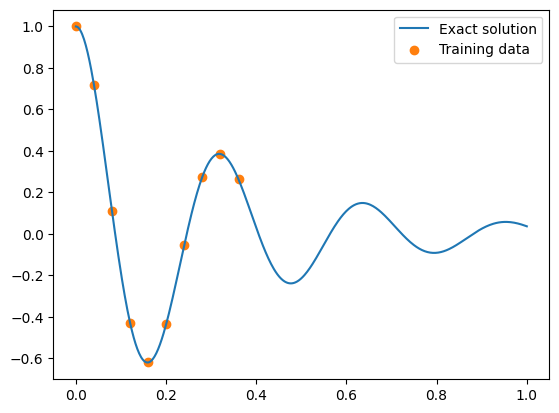

In [ ]:
def oscillator(d, w0, x):
    assert d < w0
    w = np.sqrt(w0**2-d**2)
    phi = np.arctan(-d/w)
    A = 1/(2*np.cos(phi))
    cos = torch.cos(phi+w*x)
    sin = torch.sin(phi+w*x)
    exp = torch.exp(-d*x)
    y  = exp*2*A*cos
    return y

d, w0 = 3, 20

# get the analytical solution over the full domain
x = torch.linspace(0, 1, 500).view(-1, 1)
y = oscillator(d, w0, x).view(-1, 1)
print(x.shape, y.shape)

# slice out a small number of points from the LHS of the domain
x_data = x[0:200:20]
y_data = y[0:200:20]
print(x_data.shape, y_data.shape)

plt.figure()
plt.plot(x, y, label="Exact solution")
plt.scatter(x_data, y_data, color="tab:orange", label="Training data")
plt.legend()
plt.show()

In [ ]:
def plot_result(x, y, x_data, y_data, yh, xlim_low, xlim_high, ylim_low, ylim_high, xp=None):
    "Plot training results"
    plt.figure(figsize=(8,4))
    plt.plot(x, y, color="grey", linewidth=2, alpha=0.8, label="Exact solution")
    plt.plot(x, yh, color="blue", linewidth=3, alpha=0.8, label="Neural network prediction")
    plt.scatter(x_data, y_data, s=60, color="yellow", alpha=0.4, label='Training data')

    if xp is not None:
        plt.scatter(xp, 0*torch.ones_like(xp), s=60, color="green", alpha=0.4,
                    label='Physics loss training locations')

    l = plt.legend(loc=(1.01,0.35), frameon=False, fontsize="large")
    plt.setp(l.get_texts(), color="k")
    plt.xlim(xlim_low, xlim_high)
    plt.ylim(ylim_low, ylim_high)
    plt.text(1.065,0.7,"Training step: %i"%(i+1),fontsize="xx-large",color="k")
    plt.axis("off")

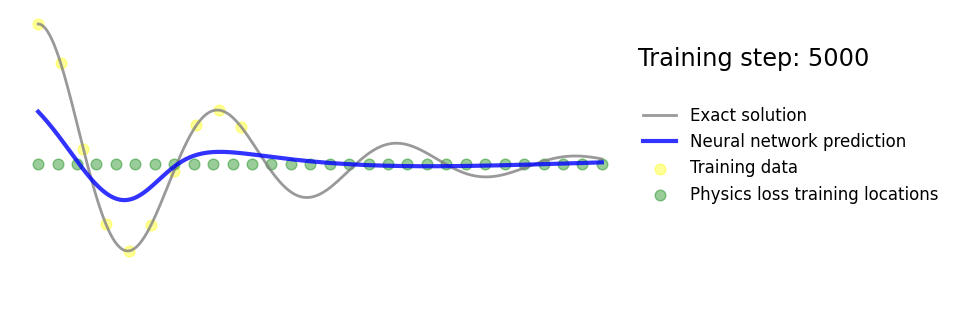

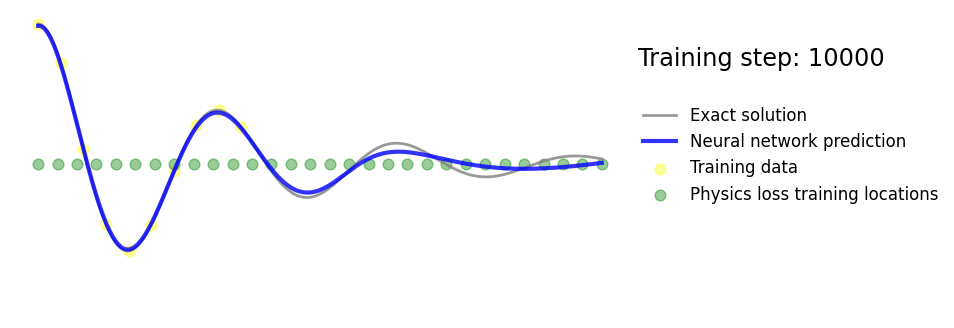

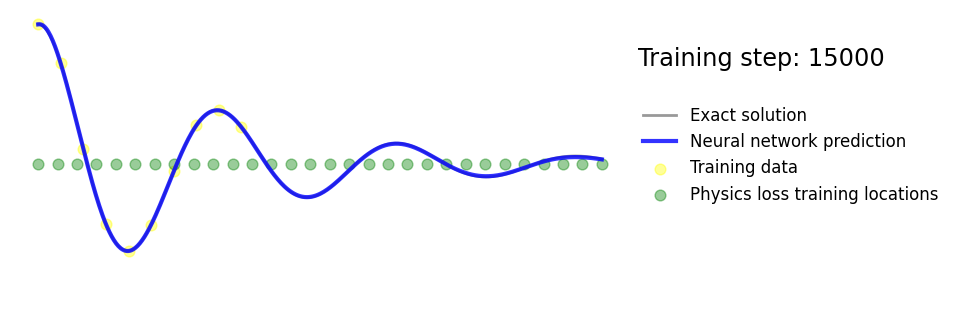

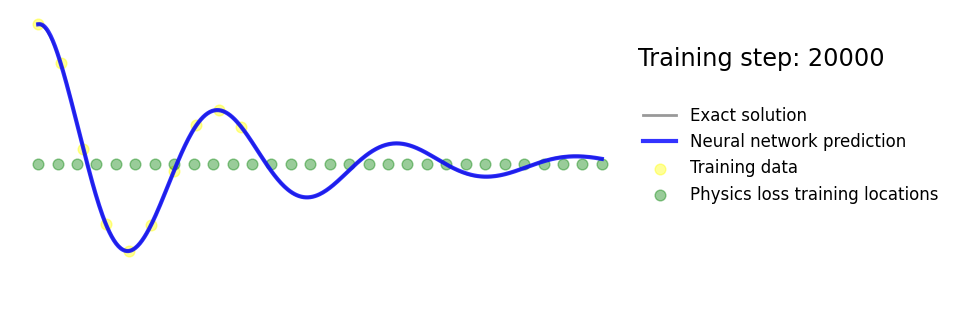

In [ ]:
x_physics = torch.linspace(0,1,30).view(-1,1).requires_grad_(True) # sample locations over the problem domain
mu, k = 2*d, w0**2

N_INPUT = 1
N_OUTPUT = 1
N_HIDDEN = 32
N_LAYERS = 2

torch.manual_seed(123)
model = FC(N_INPUT, N_OUTPUT, N_HIDDEN, N_LAYERS)
optimizer = torch.optim.Adam(model.parameters(),lr=2e-4)


data_loss_history = []
physics_loss_history = []
total_loss_history = []

#Training loop

for i in range(20000):
    optimizer.zero_grad()

    # compute the "data loss"
    yd = model(x_data)
    loss1 = torch.mean((yd-y_data)**2)# use mean squared error


    # compute the "physics loss"
    y_ph = model(x_physics)
    dx  = torch.autograd.grad(y_ph, x_physics, torch.ones_like(y_ph), create_graph=True)[0]# computes dy/dx
    dx2 = torch.autograd.grad(dx,  x_physics, torch.ones_like(dx),  create_graph=True)[0]# computes d^2y/dx^2
    physics = dx2 + mu*dx + k*y_ph # computes the residual of the 1D harmonic oscillator differential equation
    loss2 = (1e-4)*torch.mean(physics**2)

    # backpropagate joint loss
    loss = loss1 + loss2 # add two loss terms together

    data_loss_history.append(loss1.item())
    total_loss_history.append(loss.item())
    physics_loss_history.append(loss2.item())

    loss.backward()
    optimizer.step()

    # plot the result as training progresses
    if (i+1) % 5000 == 0:

        yh = model(x).detach()
        xp = x_physics.detach()
        xlim_low = -0.05
        xlim_high = 1.05
        ylim_low = -1.1
        ylim_high = 1.1
        plot_result(x,y,x_data,y_data,yh,xlim_low,xlim_high,ylim_low,ylim_high,xp)
        plt.show()


# Пример задачи с двумерным уравнением в частных производных

Нам дали уравнение в частных производных:
$$
\frac{\partial u}{\partial x}=2 \frac{\partial u}{\partial t}+u
$$
и начальное (граничное) условие:
$$
u(x,0)=6e^{-3x}
$$
- Независимые переменные: $x,t$ (входные)
- Зависимые переменные: $u$ (выходные)

Нам нужно найти $u(x,t)$  для $\forall x \in [0,2]$ и $t \in [0,1]$

Аналитическое решение:
$$
u(x,t) = 6e^{-3x-2t}
$$


In [ ]:
class FC2(nn.Module):
    "Defines a connected network"
    def __init__(self, N_INPUT, N_OUTPUT, N_HIDDEN, N_LAYERS):
        super().__init__()
        self.activation = nn.Tanh()
        self.initial_layer = nn.Linear(N_INPUT, N_HIDDEN)
        self.hidden_layers = nn.ModuleList([nn.Linear(N_HIDDEN, N_HIDDEN) for _ in range(N_LAYERS - 1)])
        self.output_layer = nn.Linear(N_HIDDEN, N_OUTPUT)  # Output for both real and imaginary parts


    def forward(self, x, t):
        inputs = torch.cat((x, t), dim=1)
        x = self.activation(self.initial_layer(inputs))
        for hidden_layer in self.hidden_layers:
            x = self.activation(hidden_layer(x))
        x = self.output_layer(x)
        return x

In [ ]:
net = FC2(2, 1, 50, 2)
mse_cost_function = torch.nn.MSELoss() # Mean squared error
optimizer = torch.optim.Adam(net.parameters())

def PINN_loss(x, t, pt_x_bc, pt_t_bc, pt_u_bc, net):

    # Loss based on BC
    net_bc_out = net(pt_x_bc, pt_t_bc) # output of u(x,t)
    mse_u = mse_cost_function(net_bc_out, pt_u_bc)

    # Loss based on PDE
    u = net(x,t) # the dependent variable u is given by the network based on independent variables x,t
    u_x = torch.autograd.grad(u.sum(), x, create_graph=True)[0] # derivative with respect to x
    u_t = torch.autograd.grad(u.sum(), t, create_graph=True)[0] # derivative with respect to t
    physics_loss = u_x - 2*u_t - u
    mse_loss = mse_cost_function(physics_loss, pt_all_zeros)

    return mse_u, mse_loss


# BC tells us that for any x in range[0,2] and time=0, the value of u is given by 6e^(-3x)
# Take say 500 random numbers of x
x_bc = np.random.uniform(low=0.0, high=2.0, size=(500,1))
t_bc = np.zeros((500,1))
# compute u based on BC
u_bc = 6*np.exp(-3*x_bc)

In [ ]:
mse_u_history = []
mse_history = []
total_loss_history = []

pt_x_bc = torch.from_numpy(x_bc).float()
pt_t_bc = torch.from_numpy(t_bc).float()
pt_u_bc = torch.from_numpy(u_bc).float()


# Training process
for epoch in range(10000):

    x_collocation = np.random.uniform(low=0.0, high=2.0, size=(500,1))
    t_collocation = np.random.uniform(low=0.0, high=1.0, size=(500,1))
    all_zeros = np.zeros((500, 1))
    pt_x_collocation = torch.from_numpy(x_collocation).float().requires_grad_(True)
    pt_t_collocation = torch.from_numpy(t_collocation).float().requires_grad_(True)
    pt_all_zeros = torch.from_numpy(all_zeros).float()

    loss1, loss2 = PINN_loss(pt_x_collocation, pt_t_collocation, pt_x_bc, pt_t_bc, pt_u_bc, net) # output of f(x,t)
    mse_u_history.append(loss1.item())
    mse_history.append(loss2.item())


    optimizer.zero_grad() # to make the gradients zero

    loss = loss1 + loss2
    total_loss_history.append(loss.item())
    loss.backward()
    optimizer.step()
    with torch.autograd.no_grad():
        if epoch % 1000 == 0:
            print(epoch,"Training Loss:",loss.data)


0 Training Loss: tensor(3.0471)
1000 Training Loss: tensor(0.0012)
2000 Training Loss: tensor(0.0002)
3000 Training Loss: tensor(4.9732e-05)
4000 Training Loss: tensor(2.9252e-05)
5000 Training Loss: tensor(3.6209e-05)
6000 Training Loss: tensor(1.5104e-05)
7000 Training Loss: tensor(5.0118e-06)
8000 Training Loss: tensor(1.4307e-05)
9000 Training Loss: tensor(2.0073e-05)


In [ ]:
import pandas as pd

df = pd.DataFrame({
    'Boundary Condition Loss': mse_u_history,
    'Physics Loss': mse_history,
    'Total Loss': total_loss_history
})

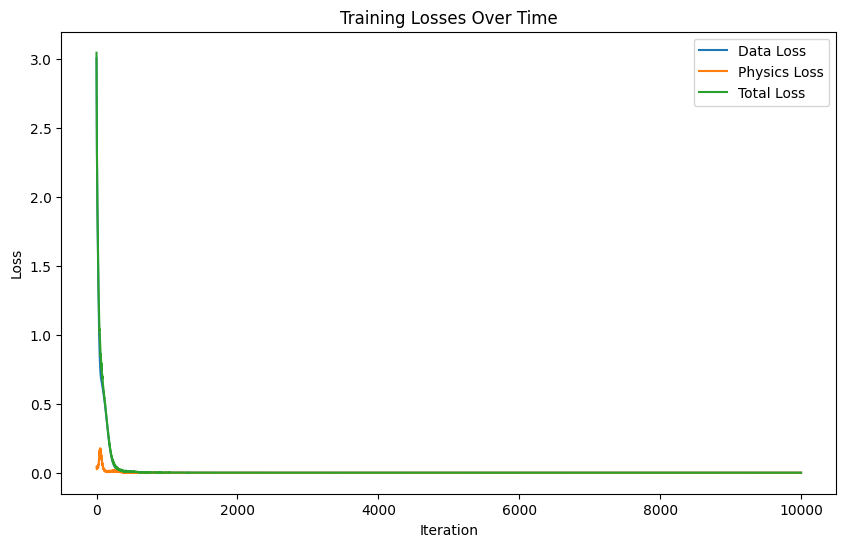

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(df['Boundary Condition Loss'], label='Data Loss')
plt.plot(df['Physics Loss'], label='Physics Loss')
plt.plot(df['Total Loss'], label='Total Loss')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.legend()
plt.title('Training Losses Over Time')
plt.show()

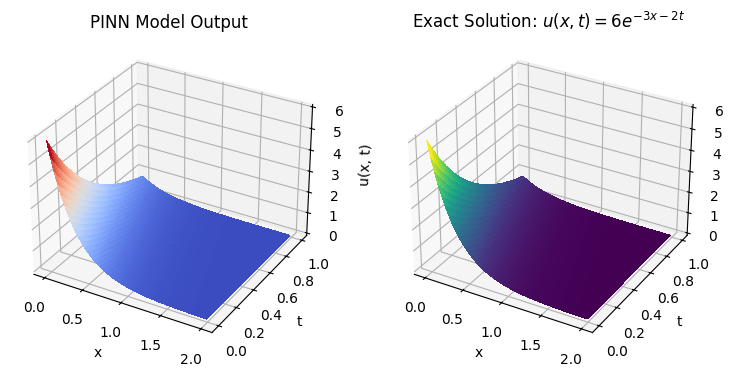

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import LinearLocator, FormatStrFormatter


fig = plt.figure(figsize=(9, 9))
ax1 = fig.add_subplot(121, projection='3d')  # Changed this line

x = np.arange(0, 2, 0.01)
t = np.arange(0, 1, 0.01)
ms_x, ms_t = np.meshgrid(x, t)
x = np.ravel(ms_x).reshape(-1, 1)
t = np.ravel(ms_t).reshape(-1, 1)

pt_x = torch.from_numpy(x).float().requires_grad_(True)
pt_t = torch.from_numpy(t).float().requires_grad_(True)
pt_u = net(pt_x, pt_t)
u = pt_u.data.cpu().numpy()
ms_u = u.reshape(ms_x.shape)

surf = ax1.plot_surface(ms_x, ms_t, ms_u, cmap=cm.coolwarm, linewidth=0, antialiased=False)

ax2 = fig.add_subplot(122, projection='3d')  # Second subplot for exact solution plot

# Generating the meshgrid for the exact solution
ms_u_exact = 6 * np.exp(-3*ms_x - 2*ms_t)

# Plotting the exact solution
surf2 = ax2.plot_surface(ms_x, ms_t, ms_u_exact, cmap=cm.viridis, linewidth=0, antialiased=False)

# Setting labels and titles for both plots
ax1.set_xlabel('x')
ax1.set_ylabel('t')
ax1.set_zlabel('u(x, t)')
ax1.set_title('PINN Model Output')

ax2.set_xlabel('x')
ax2.set_ylabel('t')
ax2.set_zlabel('u(x, t)')
ax2.set_title('Exact Solution: $u(x,t) = 6e^{-3x-2t}$')

plt.show()

# KAN

Сети Колмогорова — Арнольда (KAN) были предложены Лю и соавторами (2024) как обобщение теоремы Колмогорова — Арнольда о представлении с целью превзойти многослойные перцептроны в решении небольших задач в области искусственного интеллекта и научных задач.  До появления KAN в многочисленных исследованиях изучалась связь теоремы с нейронными сетями или она использовалась как основа для разработки новых сетевых архитектур.

В 1980-х и 1990-х годах в рамках ранних исследований метод КАРП применялся для проектирования нейронных сетей. Куркова и др. (1992), Хехт-Нильсен (1987) и Нис (1994) заложили теоретические основы для создания многослойных сетей на основе метода КАРП. Игельник и др. (2003) представили сплайн-сеть Колмогорова, использующую кубические сплайны для моделирования сложных функций.

Теорема Колмогорова — Арнольда о представлении утверждает, что если $f$ — многомерная непрерывная функция
в ограниченной области, то её можно представить в виде конечной композиции непрерывных функций от
одной переменной и бинарной операции сложения. В частности, для гладкой функции $f : [0,1]^n \to \mathbb{R}$


$$f(x) = f(x_1,...,x_n)=\sum_{q=1}^{2n+1}\Phi_q(\sum_{p=1}^n \phi_{q,p}(x_p))$$

где $\phi_{q,p}:[0,1]\to\mathbb{R}$ и $\Phi_q:\mathbb{R}\to\mathbb{R}$. В некотором смысле они показали, что единственной настоящей многомерной функцией является сложение, поскольку любую другую функцию можно представить с помощью одномерных функций и сложения. Однако это двухслойное представление Колмогорова — Арнольда с шириной слоя $(2n+1)$ может быть негладким из-за ограниченной выразительности. Мы расширяем его выразительные возможности, обобщая его на случай произвольной глубины и ширины.



### Kolmogorov-Arnold Network (KAN)

Представление Колмогорова-Арнольда может быть записано в матричном виде

$$f(x)={\bf \Phi}_{\rm out}\circ{\bf \Phi}_{\rm in}\circ {\bf x}$$

где

$${\bf \Phi}_{\rm in}= \begin{pmatrix} \phi_{1,1}(\cdot) & \cdots & \phi_{1,n}(\cdot) \\ \vdots & & \vdots \\ \phi_{2n+1,1}(\cdot) & \cdots & \phi_{2n+1,n}(\cdot) \end{pmatrix},\quad {\bf \Phi}_{\rm out}=\begin{pmatrix} \Phi_1(\cdot) & \cdots & \Phi_{2n+1}(\cdot)\end{pmatrix}$$

Мы замечаем, что и ${\bf \Phi}_{\rm in}$ и ${\bf \Phi}_{\rm out}$ являются частными случаями следующей функциональной матрицы ${\bf \Phi}$ (с $n_{\rm in}$ входами и $n_{\rm out}$ выходами), которую мы называем слоем Колмогорова — Арнольда:

$${\bf \Phi}= \begin{pmatrix} \phi_{1,1}(\cdot) & \cdots & \phi_{1,n_{\rm in}}(\cdot) \\ \vdots & & \vdots \\ \phi_{n_{\rm out},1}(\cdot) & \cdots & \phi_{n_{\rm out},n_{\rm in}}(\cdot) \end{pmatrix}$$

${\bf \Phi}_{\rm in}$ соответствует $n_{\rm in}=n, n_{\rm out}=2n+1$, а ${\bf \Phi}_{\rm out}$ — $n_{\rm in}=2n+1, n_{\rm out}=1$.

Определив слой, мы можем построить сеть Колмогорова — Арнольда, просто объединив слои! Допустим, у нас есть $L$ слоёв, причём $l^{\rm th}$ слой ${\bf \Phi}_l$ имеет форму $(n_{l+1}, n_{l})$. Тогда вся сеть выглядит так:

$${\rm KAN}({\bf x})={\bf \Phi}_{L-1}\circ\cdots \circ{\bf \Phi}_1\circ{\bf \Phi}_0\circ {\bf x}$$

В отличие от него, многослойный перцептрон состоит из чередующихся линейных слоев ${\bf W}_l$ и нелинейных функций $\sigma$:

$${\rm MLP}({\bf x})={\bf W}_{L-1}\circ\sigma\circ\cdots\circ {\bf W}_1\circ\sigma\circ {\bf W}_0\circ {\bf x}$$

KAN можно легко представить визуально. (1) KAN — это просто набор слоев KAN. (2) Каждый слой KAN можно представить как полносвязный слой с одномерной функцией на каждом ребре. Рассмотрим пример ниже.

In [ ]:
!pip install git+https://github.com/KindXiaoming/pykan.git

  Cloning https://github.com/KindXiaoming/pykan.git to /tmp/pip-req-build-y69u6cxu
  Running command git clone --filter=blob:none --quiet https://github.com/KindXiaoming/pykan.git /tmp/pip-req-build-y69u6cxu
  Resolved https://github.com/KindXiaoming/pykan.git to commit ecde4ec3274d3bef1ad737479cf126aed38ab530
  Preparing metadata (setup.py) ... done
  Created wheel for pykan: filename=pykan-0.2.8-py3-none-any.whl size=78309 sha256=23f52982dba8b5674fd016341d3b02551442ab7e9cad86ac5d9a642a53e35b59
  Stored in directory: /tmp/pip-ephem-wheel-cache-1_1macib/wheels/fe/d7/fd/0761cdc11f5bfb103a1ebadb6bea12c86f64f62bc6b1303e06
Successfully built pykan


In [ ]:
from kan import *
torch.set_default_dtype(torch.float64)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# create a KAN: 2D inputs, 1D output, and 5 hidden neurons. cubic spline (k=3), 5 grid intervals (grid=5).
model = KAN(width=[1,5,5,1], grid=3, k=3, seed=42, device=device)

cpu
checkpoint directory created: ./model
saving model version 0.0


In [ ]:
from kan.utils import create_dataset
# create dataset f(x,y) = exp(sin(pi*x)+y^2)
f = lambda x: torch.sin(2*torch.pi*x[:,[0]])
dataset = create_dataset(f, n_var=1, device=device)
dataset['train_input'].shape, dataset['train_label'].shape

(torch.Size([1000, 1]), torch.Size([1000, 1]))

In [ ]:
mind = dataset['train_input'].min()
maxd = dataset['train_input'].max()

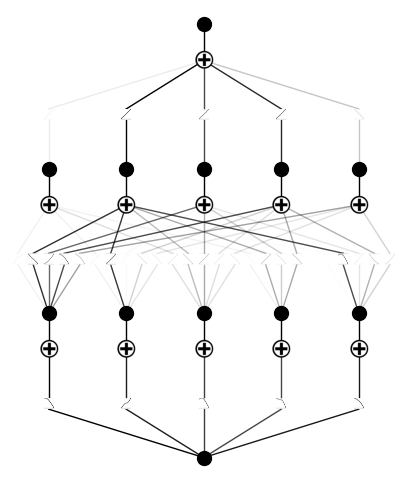

In [ ]:
# plot KAN at initialization
model(dataset['train_input']);
model.plot()

In [ ]:
# train the model
model.speed() # to speed up training
model.fit(dataset, opt="LBFGS", steps=400, lamb=0.01);

setting lamb=0. If you want to set lamb > 0, set self.save_act=True


| train_loss: 2.69e-04 | test_loss: 2.82e-04 | reg: 0.00e+00 | : 100%|█| 400/400 [03:55<00:00,  1.70


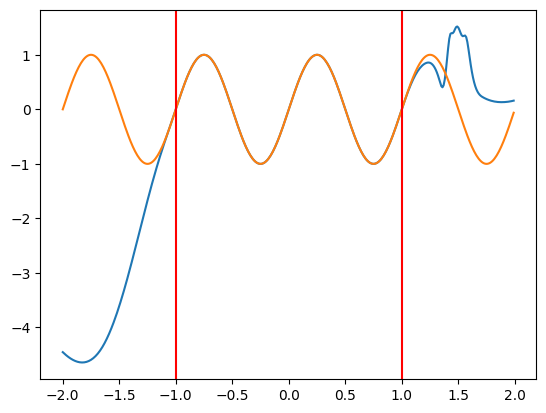

In [ ]:
model_data = model(torch.arange(-2,2,0.01).unsqueeze(1))
plt.plot(torch.arange(-2,2,0.01).unsqueeze(1) , model_data.detach().numpy())
plt.plot(torch.arange(-2,2,0.01).unsqueeze(1), f(torch.arange(-2,2,0.01).unsqueeze(1)))


plt.axvline(x=mind, color='red')
plt.axvline(x=maxd, color='red')